# Mission 4 — Prédiction du churn (apprentissage supervisé)
**TP Customer Intelligence & AI Marketing Strategy — cas NovaMarket**

**Objectif :** prédire quels clients risquent de partir dans les 90 jours, comparer deux modèles, choisir un seuil selon le coût métier des erreurs, puis transformer le score en campagne de rétention.

**Plan**

0. Mise en place
1. Données et variable cible
2. Choix des variables explicatives
3. Séparation apprentissage / test (stratifiée)
4. Modèle 1 : régression logistique
5. Modèle 2 : arbre de décision
6. Comparaison des modèles
7. Matrices de confusion
8. Variables importantes
9. Choix du seuil selon le coût métier
10. Le cas de la récence : fuite d'information ?
11. Du score à la campagne de rétention
12. Exports : `churn_predictions.csv` et `model_metrics.json`
13. Limites

## 0. Mise en place

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/TP_NovaMarket'
except ImportError:
    BASE = os.environ.get('TP_BASE', '..')

DATA = os.path.join(BASE, 'data')
OUT = os.path.join(BASE, 'outputs')
os.makedirs(OUT, exist_ok=True)

RANDOM_STATE = 42
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

## 1. Données et variable cible
**Pourquoi un modèle supervisé a besoin d'une cible.** Le modèle apprend à partir d'exemples dont on connaît déjà la réponse : ici, les clients pour lesquels on sait s'ils sont partis (`churn_90d = 1`) ou restés (`churn_90d = 0`). Sans cette colonne, il n'y a rien à apprendre ni à vérifier. C'est la différence avec la segmentation de la mission 3, qui n'avait pas de « bonne réponse ».

In [2]:
clients = pd.read_csv(os.path.join(OUT, 'customers_prepared.csv'))
segments = pd.read_csv(os.path.join(OUT, 'customer_segments.csv'))[['customer_id', 'segment']]
clients = clients.merge(segments, on='customer_id', how='left')

CIBLE = 'churn_90d'
taux = clients[CIBLE].mean()
print(f'{len(clients)} clients — {clients[CIBLE].sum()} partis ({taux:.1%}), {(1 - clients[CIBLE]).sum()} restés')
print(f'Un modèle qui prédit « personne ne part » aurait déjà {1 - taux:.1%} d\'accuracy : '
      'c\'est pourquoi l\'accuracy seule est trompeuse.')

1500 clients — 348 partis (23.2%), 1152 restés
Un modèle qui prédit « personne ne part » aurait déjà 76.8% d'accuracy : c'est pourquoi l'accuracy seule est trompeuse.


## 2. Choix des variables explicatives
On garde les informations **connues au moment où l'on calcule le score** et on retire les **doublons d'information** :

| Retirée | Raison |
|---|---|
| `customer_id` | Identifiant, aucune information |
| `revenue_12m_eur` | = commandes × panier moyen (déjà présents) |
| `nb_categories` | Corrélée à 0,87 avec le nombre de commandes |
| `email_clicks_90d`, `emails_received_90d` | Résumées par `taux_clic_email` |
| `log_...` | Versions transformées pour le K-Means, inutiles ici |
| `segment` | Construit à partir des mêmes variables : redondant |

`region` et `acquisition_channel` sont transformées en colonnes 0/1 (**one-hot encoding**).

In [3]:
VARIABLES_NUM = ['age', 'days_since_last_order', 'orders_12m', 'avg_order_value_eur', 'sessions_90d',
                 'taux_clic_email', 'returns_12m', 'support_tickets_90d', 'satisfaction_score',
                 'sans_commande', 'part_achats_mobile', 'part_achats_magasin']
VARIABLES_CAT = ['region', 'acquisition_channel']

X = pd.get_dummies(clients[VARIABLES_NUM + VARIABLES_CAT], columns=VARIABLES_CAT, drop_first=True, dtype=int)
y = clients[CIBLE]
print('Nombre de variables explicatives :', X.shape[1])
list(X.columns)

Nombre de variables explicatives : 20


['age',
 'days_since_last_order',
 'orders_12m',
 'avg_order_value_eur',
 'sessions_90d',
 'taux_clic_email',
 'returns_12m',
 'support_tickets_90d',
 'satisfaction_score',
 'sans_commande',
 'part_achats_mobile',
 'part_achats_magasin',
 'region_Hauts-de-France',
 'region_Nouvelle-Aquitaine',
 'region_Occitanie',
 'region_Île-de-France',
 'acquisition_channel_Email',
 'acquisition_channel_Paid Social',
 'acquisition_channel_Referral',
 'acquisition_channel_SEO']

## 3. Séparation apprentissage / test (stratifiée)
- **75 %** des clients servent à **entraîner** les modèles, **25 %** sont gardés de côté pour les **évaluer** sur des clients qu'ils n'ont jamais vus.
- La séparation est **stratifiée** : le taux de churn (23 %) est le même dans les deux jeux. Sans cela, le hasard pourrait mettre trop ou trop peu de partants dans le test.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

pd.DataFrame({'clients': [len(y_train), len(y_test)],
              'taux_churn_%': [y_train.mean() * 100, y_test.mean() * 100]},
             index=['apprentissage', 'test']).round(1)

,clients,taux_churn_%
apprentissage,1125,23.2
test,375,23.2


## 4. Modèle 1 : régression logistique
Elle calcule une **probabilité de départ** à partir d'une combinaison pondérée des variables. Les variables sont standardisées pour que leurs coefficients soient comparables.

In [5]:
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
logit.fit(X_train, y_train)
proba_logit = logit.predict_proba(X_test)[:, 1]

## 5. Modèle 2 : arbre de décision
L'arbre pose une suite de questions simples (« dernière commande il y a plus de X jours ? »). On limite sa **profondeur** pour qu'il reste lisible et ne « récite » pas les données d'apprentissage (sur-apprentissage). La profondeur est choisie par **validation croisée** sur le jeu d'apprentissage.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
choix_profondeur = {}
for prof in [2, 3, 4, 5, 6]:
    arbre_test = DecisionTreeClassifier(max_depth=prof, min_samples_leaf=20, random_state=RANDOM_STATE)
    choix_profondeur[prof] = cross_val_score(arbre_test, X_train, y_train, cv=cv, scoring='roc_auc').mean()
display(pd.Series(choix_profondeur, name='ROC-AUC moyen (validation croisée)').round(3).to_frame())

# On retient la profondeur 4 : performance équivalente aux autres, règles encore lisibles
arbre = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=RANDOM_STATE)
arbre.fit(X_train, y_train)
proba_arbre = arbre.predict_proba(X_test)[:, 1]

,ROC-AUC moyen (validation croisée)
2,0.849
3,0.862
4,0.857
5,0.841
6,0.837


**Lecture :** la profondeur change peu la performance (ROC-AUC entre 0,83 et 0,86). On prend **4 niveaux** : assez pour capter les combinaisons utiles, et un arbre encore lisible pour une équipe marketing.

## 6. Comparaison des modèles (seuil par défaut 0,5)
- **Accuracy** : part de bonnes prédictions, trompeuse quand les classes sont déséquilibrées.
- **Précision** : parmi les clients signalés « à risque », combien partent vraiment ? Elle mesure le **gaspillage** de la campagne.
- **Rappel (recall)** : parmi les clients qui partent vraiment, combien le modèle en repère-t-il ? Il mesure les **partants ratés**.
- **F1** : compromis entre précision et rappel.
- **ROC-AUC** : capacité à **classer** les clients du plus risqué au moins risqué, quel que soit le seuil (0,5 = hasard, 1 = parfait).

In [7]:
def metriques(y_vrai, proba, seuil=0.5):
    pred = (proba >= seuil).astype(int)
    return {'accuracy': accuracy_score(y_vrai, pred), 'precision': precision_score(y_vrai, pred),
            'recall': recall_score(y_vrai, pred), 'f1': f1_score(y_vrai, pred),
            'roc_auc': roc_auc_score(y_vrai, proba)}

comparaison = pd.DataFrame({
    'Régression logistique': metriques(y_test, proba_logit),
    'Arbre de décision': metriques(y_test, proba_arbre),
    'Référence « personne ne part »': {'accuracy': 1 - y_test.mean(), 'precision': 0, 'recall': 0, 'f1': 0, 'roc_auc': 0.5},
}).T.round(3)
comparaison

,accuracy,precision,recall,f1,roc_auc
Régression logistique,0.853,0.695,0.655,0.675,0.880
Arbre de décision,0.851,0.701,0.621,0.659,0.834
Référence « personne ne part »,0.768,0.000,0.000,0.000,0.500


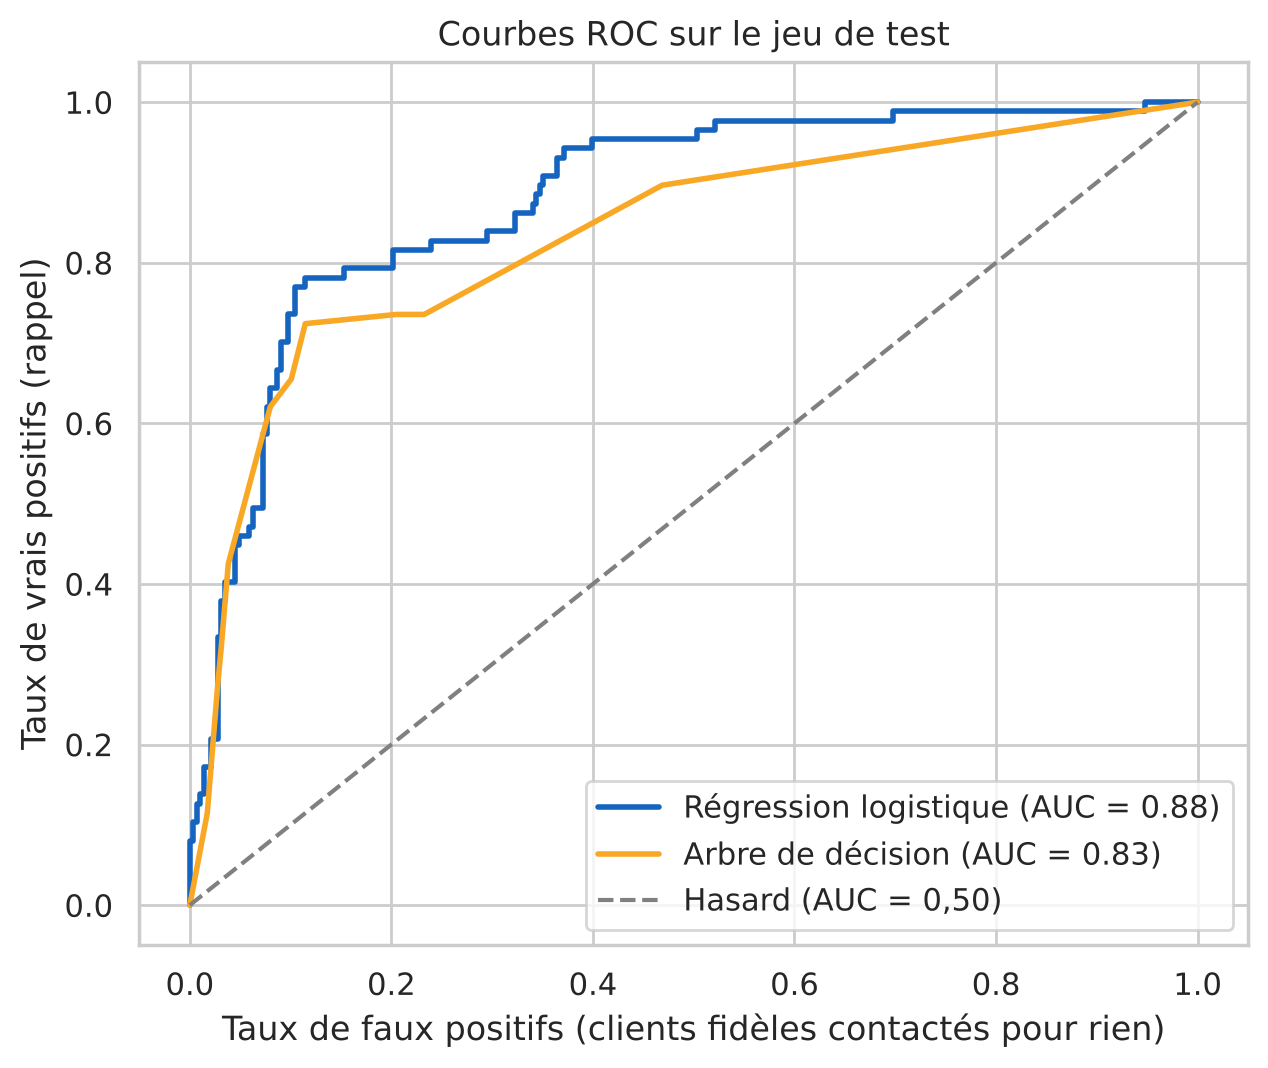

In [8]:
plt.figure(figsize=(6.5, 5.5))
for nom, proba, coul in [('Régression logistique', proba_logit, '#1565C0'), ('Arbre de décision', proba_arbre, '#F9A825')]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f'{nom} (AUC = {roc_auc_score(y_test, proba):.2f})', color=coul, lw=2)
plt.plot([0, 1], [0, 1], ls='--', color='grey', label='Hasard (AUC = 0,50)')
plt.xlabel('Taux de faux positifs (clients fidèles contactés pour rien)')
plt.ylabel('Taux de vrais positifs (rappel)')
plt.title('Courbes ROC sur le jeu de test'); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

**Lecture :**
- **La régression logistique est le meilleur modèle** : ROC-AUC d'environ 0,88 contre 0,83 pour l'arbre. Elle classe mieux les clients par niveau de risque.
- **Au seuil de 0,5**, les deux modèles ratent encore environ un tiers des partants (rappel d'environ 0,65). Le seuil par défaut n'est pas adapté à l'enjeu : on le corrige à l'étape 9.
- **L'accuracy** (environ 85 %) n'est qu'à 8 points de la référence naïve, qui obtient 77 % sans rien prédire.

**Modèle retenu : la régression logistique.**

## 7. Matrices de confusion (seuil 0,5)
| | Prédit : reste | Prédit : part |
|---|---|---|
| **Reste vraiment** | Vrai négatif | **Faux positif** : client fidèle contacté pour rien |
| **Part vraiment** | **Faux négatif** : partant raté, perdu sans action | Vrai positif : partant repéré |

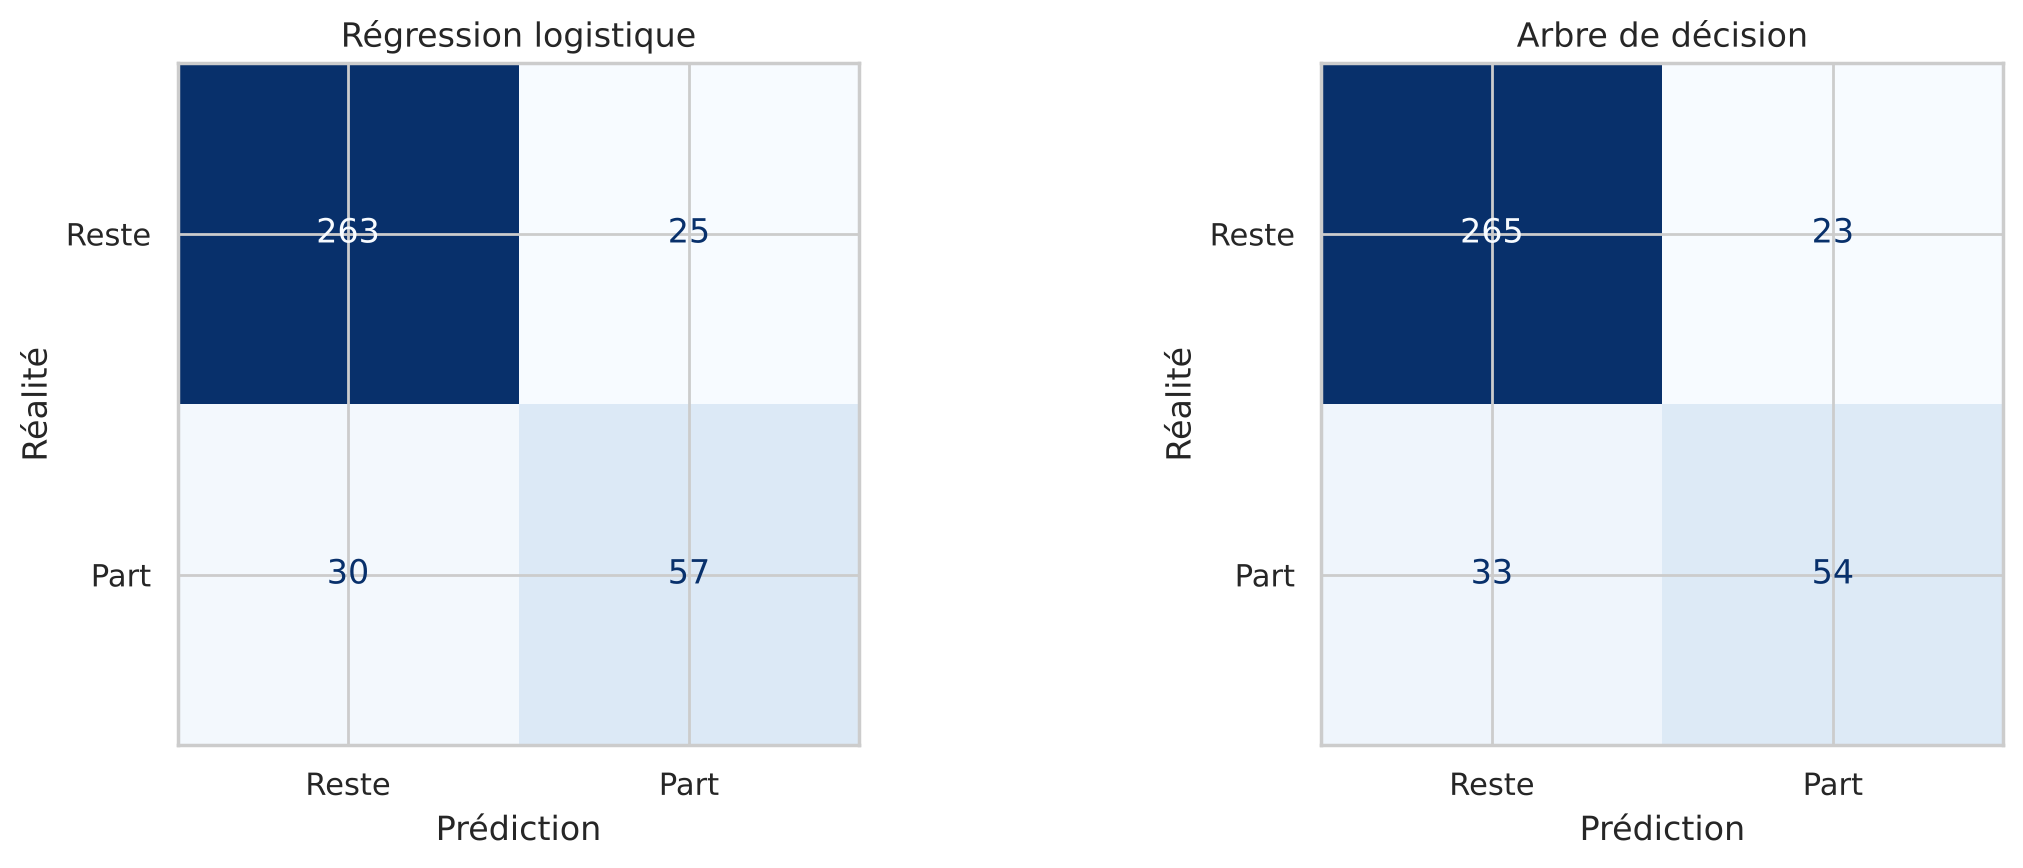

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, nom, proba in [(axes[0], 'Régression logistique', proba_logit), (axes[1], 'Arbre de décision', proba_arbre)]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, (proba >= 0.5).astype(int)),
                           display_labels=['Reste', 'Part']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nom); ax.set_xlabel('Prédiction'); ax.set_ylabel('Réalité')
plt.tight_layout(); plt.show()

**Lecture (régression logistique, seuil 0,5) :** sur 87 partants dans le test, le modèle en repère 57 et en **rate 30**. Il signale aussi 25 clients fidèles à tort. Le vrai problème est donc le nombre de **faux négatifs** : ces clients partiront sans avoir reçu aucune action.

## 8. Variables importantes

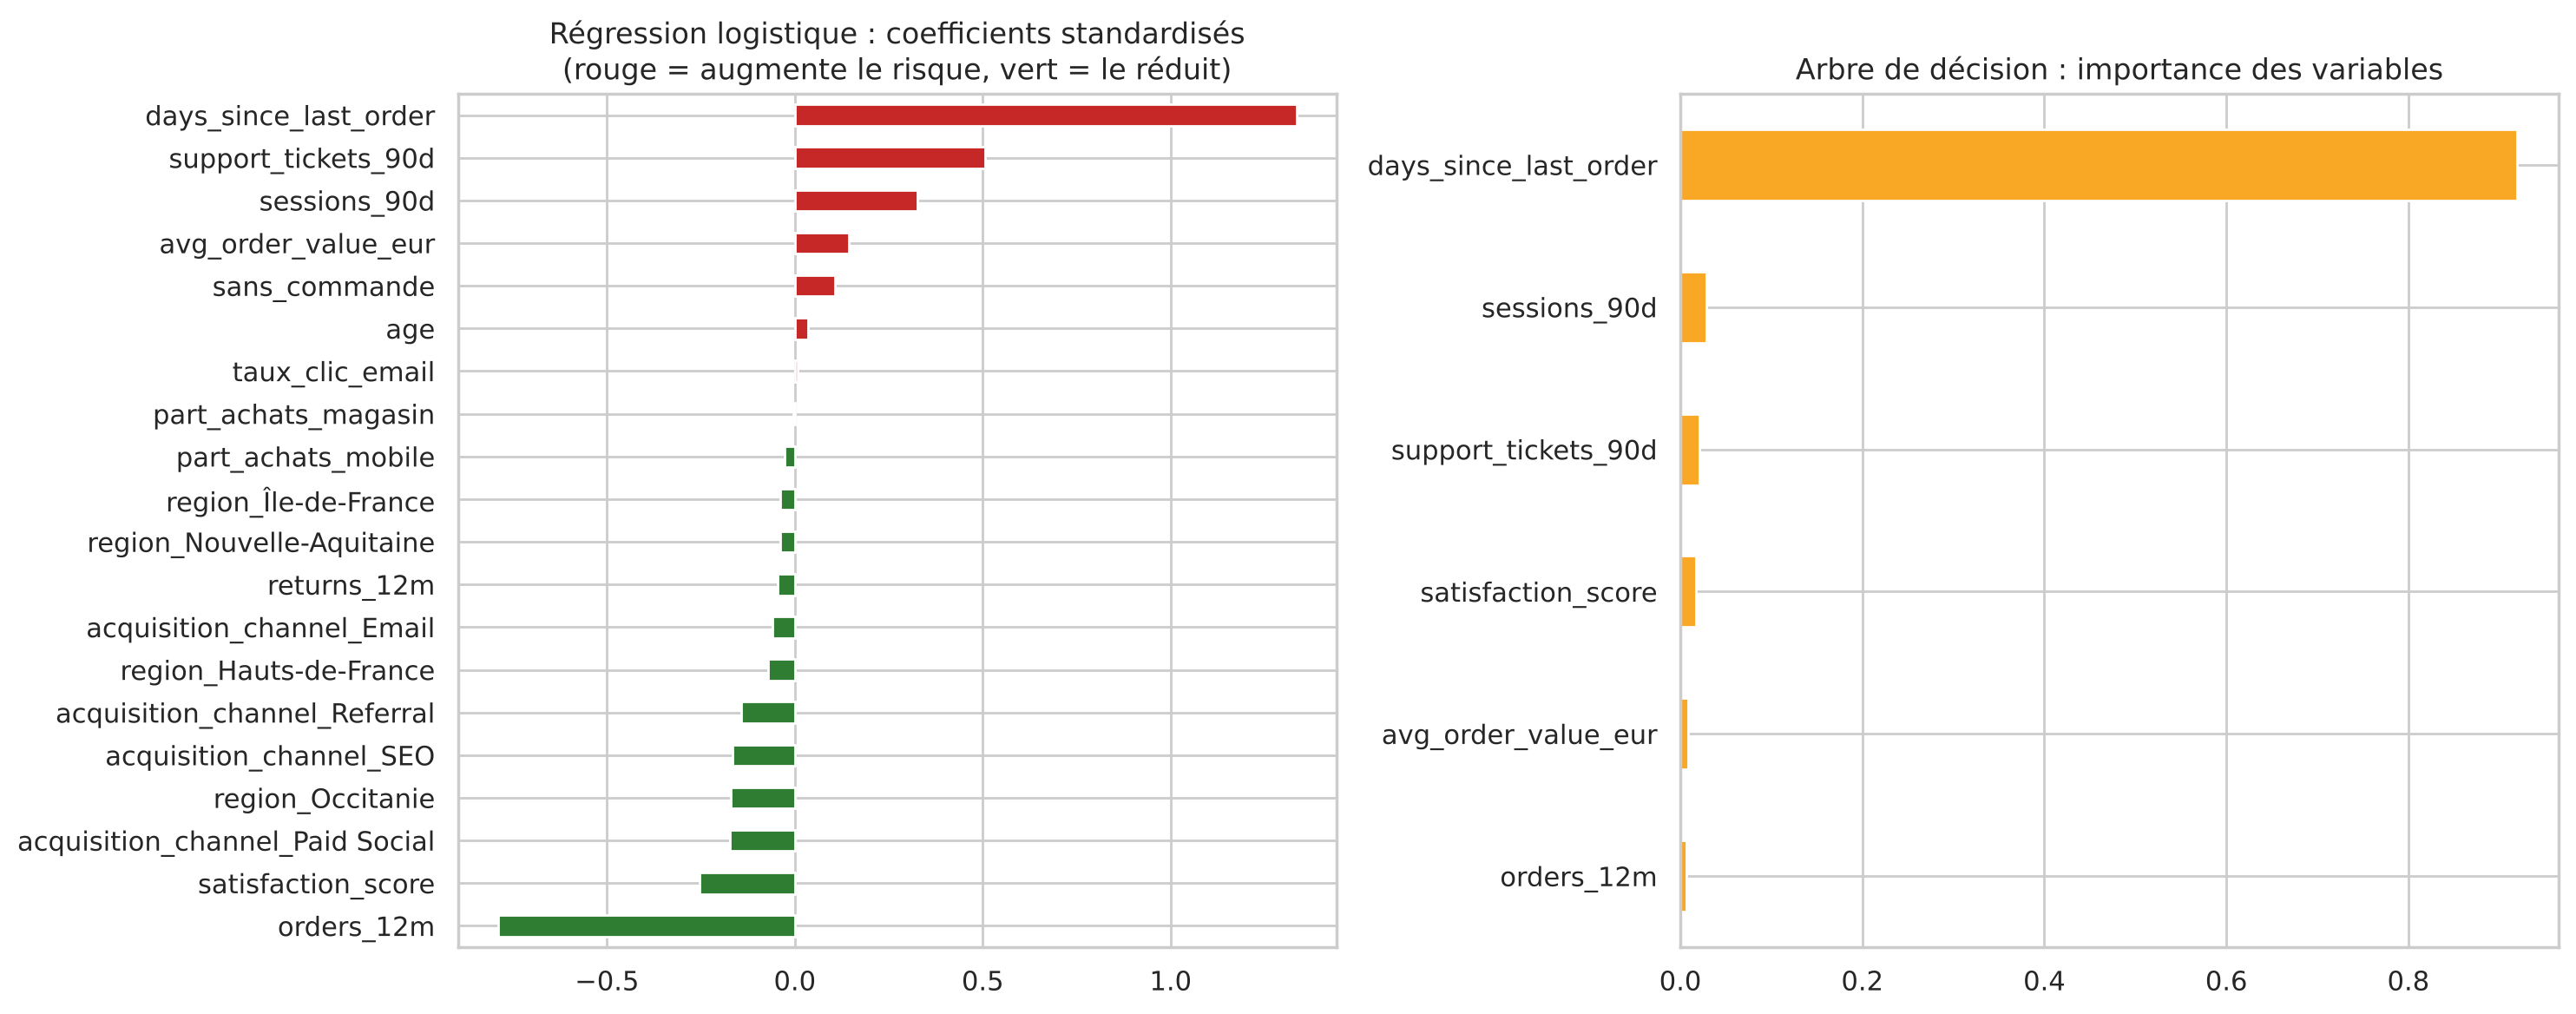

In [10]:
coefs = pd.Series(logit[-1].coef_[0], index=X.columns).sort_values()
importances = pd.Series(arbre.feature_importances_, index=X.columns).sort_values()
importances = importances[importances > 0]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
coefs.plot.barh(ax=axes[0], color=np.where(coefs > 0, '#C62828', '#2E7D32'))
axes[0].set_title('Régression logistique : coefficients standardisés\n(rouge = augmente le risque, vert = le réduit)')
importances.plot.barh(ax=axes[1], color='#F9A825')
axes[1].set_title("Arbre de décision : importance des variables")
plt.tight_layout(); plt.show()

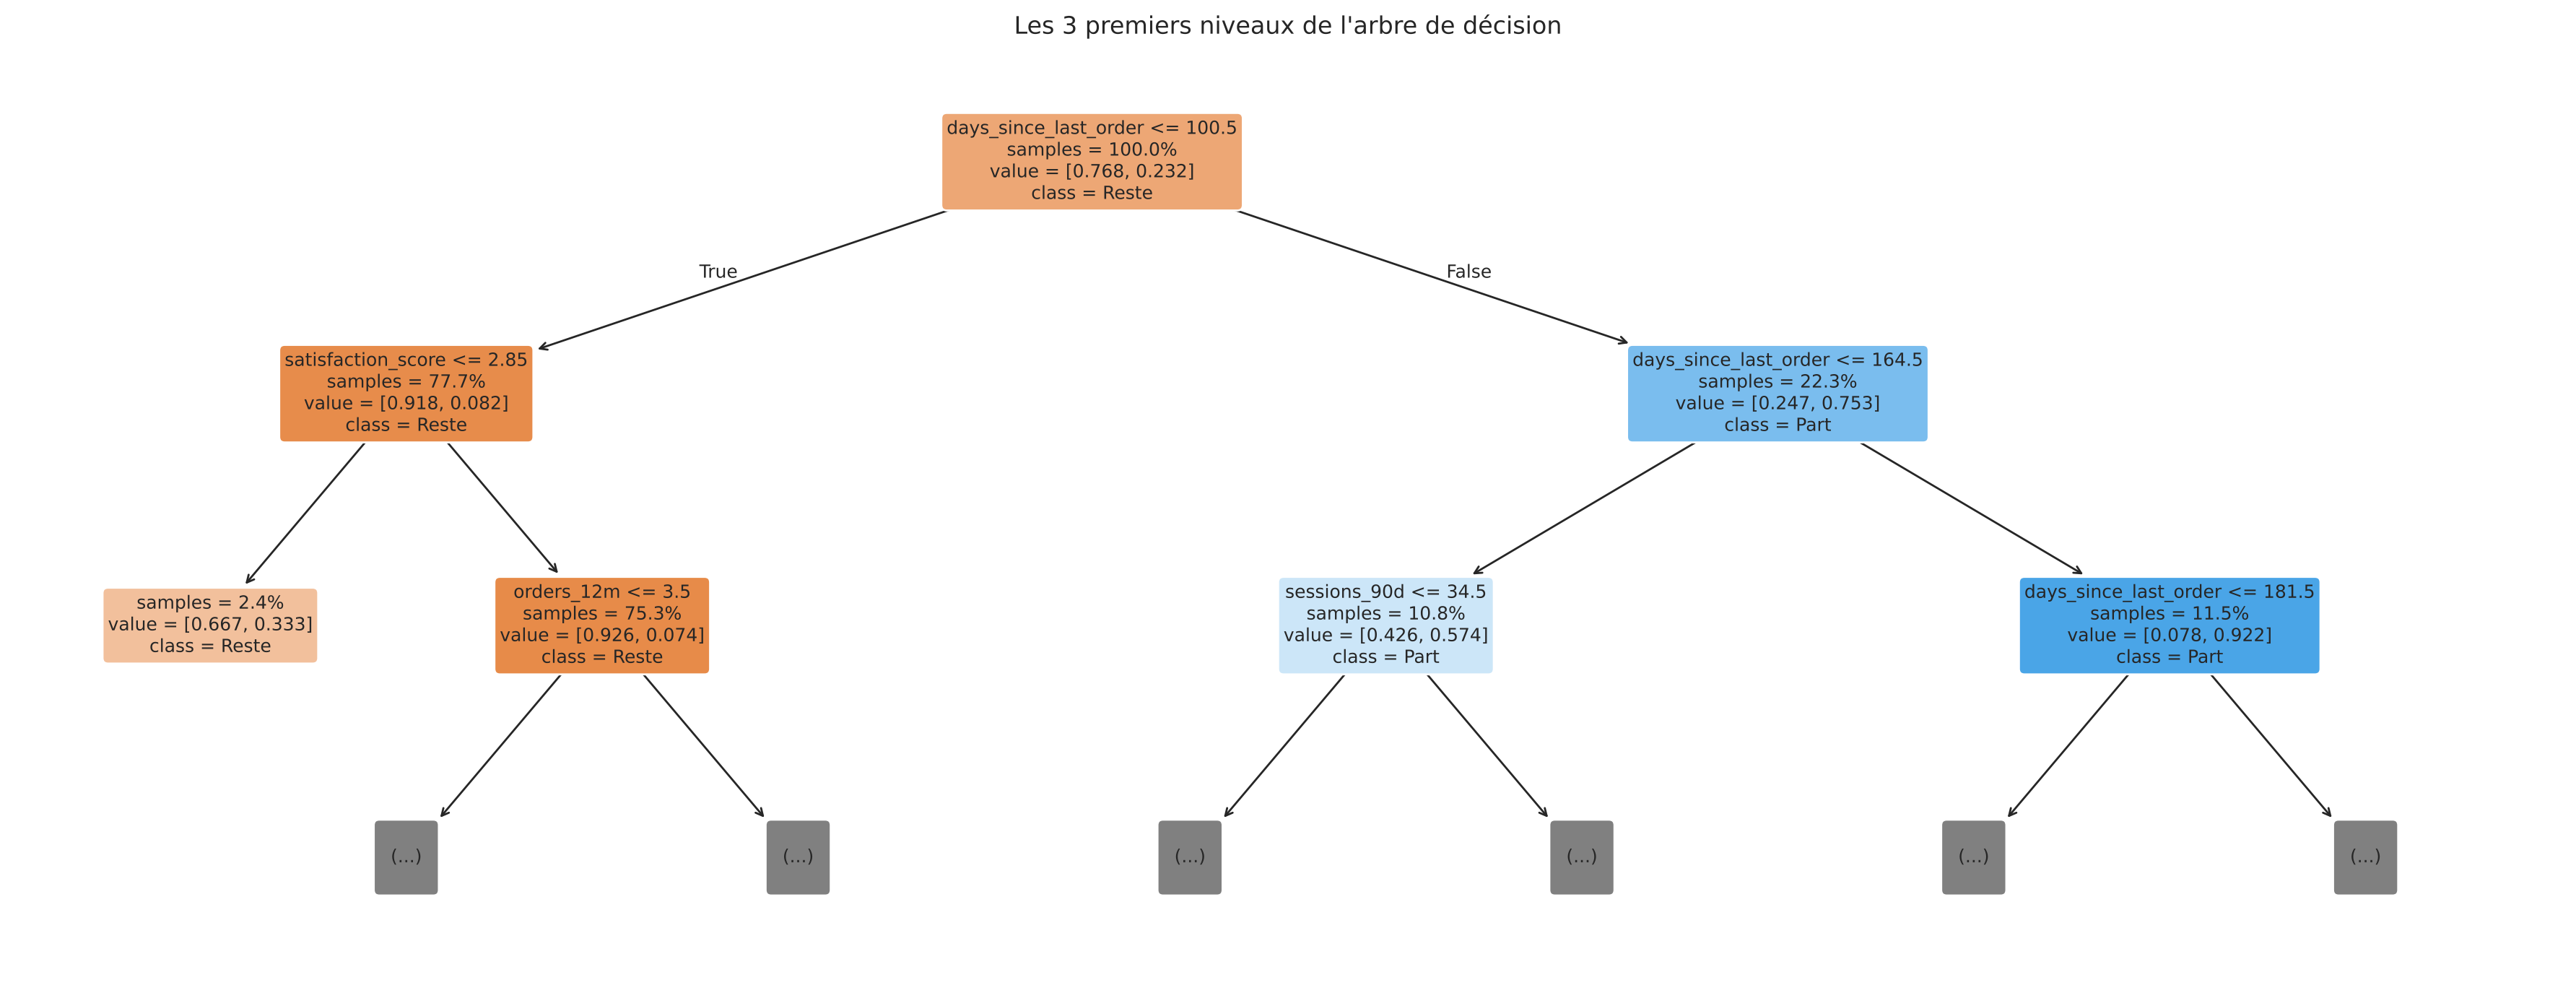

In [11]:
plt.figure(figsize=(18, 7))
plot_tree(arbre, feature_names=X.columns, class_names=['Reste', 'Part'], filled=True,
          max_depth=2, fontsize=9, impurity=False, proportion=True, rounded=True)
plt.title("Les 3 premiers niveaux de l'arbre de décision")
plt.tight_layout(); plt.show()

In [12]:
# Taux de churn observé selon la récence : la relation est très forte
tranches = pd.cut(clients['days_since_last_order'], [0, 30, 60, 90, 120, 180, 240],
                  labels=['0-30 j', '31-60 j', '61-90 j', '91-120 j', '121-180 j', '181-240 j'])
(clients.groupby(tranches, observed=True)[CIBLE].agg(taux_churn_pct='mean', clients='size')
 .assign(taux_churn_pct=lambda d: (d['taux_churn_pct'] * 100).round(1)))

,taux_churn_pct,clients
days_since_last_order,,
0-30 j,6.4,549
31-60 j,6.2,290
61-90 j,11.4,236
91-120 j,36.6,145
121-180 j,65.8,149
181-240 j,89.3,131


**Lecture :**
- **La récence est de loin le premier facteur de risque.** Le churn passe d'environ 6 % pour une dernière commande de moins de 60 jours à **près de 90 %** au-delà de 180 jours. L'arbre fait presque toute sa première coupure sur cette variable.
- **La fréquence d'achat protège** : plus un client commande, moins il part.
- **Les tickets support augmentent le risque**, et **la satisfaction le réduit**. Ce sont deux leviers sur lesquels NovaMarket peut agir.
- **Région et canal d'acquisition ne pèsent presque rien**, ce qui est cohérent avec la mission 3.
- **Prudence sur les sessions.** Leur coefficient est positif alors qu'elles sont corrélées aux commandes (0,84). Quand deux variables se recouvrent, la régression répartit l'effet entre elles : on ne lit pas ce coefficient seul. Un coefficient décrit une **association**, pas une cause.

## 9. Choix du seuil selon le coût métier
Le seuil de 0,5 est une convention mathématique, pas une décision métier. On le choisit en comparant **ce que coûte chaque type d'erreur** :

| Erreur | Ce qu'elle coûte | Hypothèse retenue |
|---|---|---|
| **Faux négatif** (partant raté) | Le client part sans action : on perd sa marge annuelle | **100 €** (CA moyen d'un partant ≈ 214 €/an × marge d'environ 50 %) |
| **Faux positif** (fidèle contacté pour rien) | Bon de réduction utilisé par un client qui serait resté + coût du contact | **20 €** |

Un faux négatif coûte donc **5 fois plus** qu'un faux positif : il vaut mieux contacter un peu trop large.

**Méthode rigoureuse :** le seuil est choisi sur le **jeu d'apprentissage** (par validation croisée), puis vérifié sur le **jeu de test**. Le choisir directement sur le test reviendrait à « tricher » avec les données d'évaluation.

*Les montants sont des hypothèses pédagogiques, à valider avec la finance et le CRM.*

Seuil qui minimise le coût sur le jeu d'apprentissage : 0.2


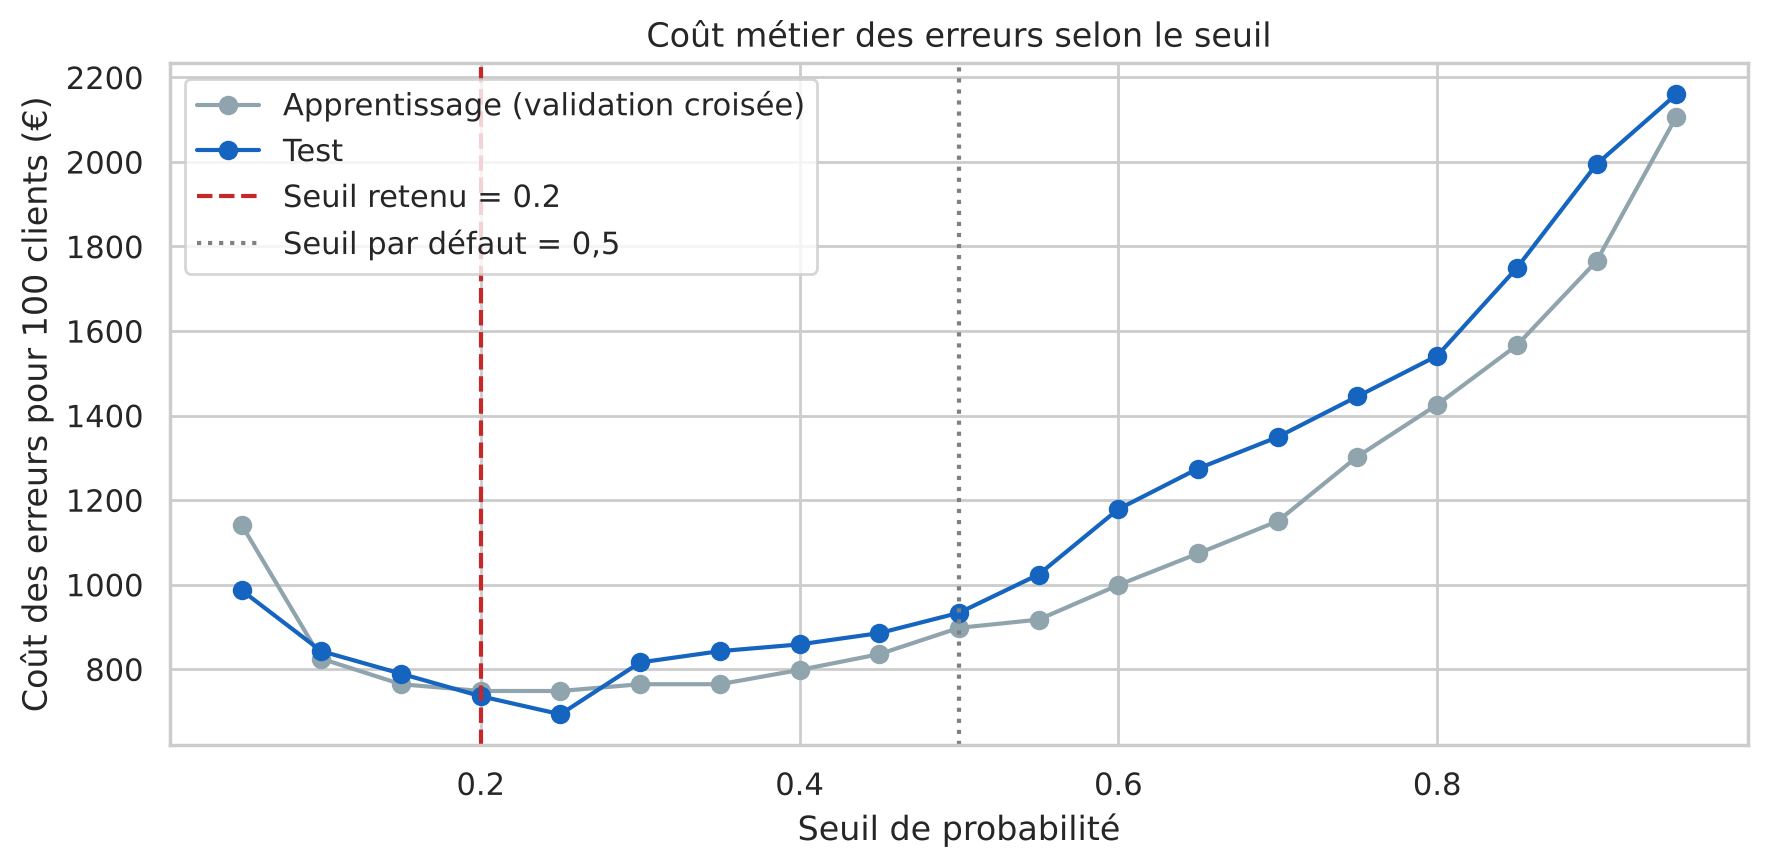

In [13]:
COUT_FN = 100   # € perdus par partant non contacté
COUT_FP = 20    # € dépensés pour un client fidèle contacté
SEUILS = np.round(np.arange(0.05, 0.96, 0.05), 2)

def cout_total(y_vrai, proba, seuil, cout_fn=COUT_FN, cout_fp=COUT_FP):
    pred = proba >= seuil
    fn = ((~pred) & (y_vrai == 1)).sum()
    fp = (pred & (y_vrai == 0)).sum()
    return fn * cout_fn + fp * cout_fp

# Probabilités « hors échantillon » sur le jeu d'apprentissage (validation croisée)
proba_cv = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                             X_train, y_train, cv=cv, method='predict_proba')[:, 1]
couts_train = pd.Series({s: cout_total(y_train.values, proba_cv, s) for s in SEUILS})
SEUIL = float(couts_train.idxmin())
print(f'Seuil qui minimise le coût sur le jeu d\'apprentissage : {SEUIL}')

couts_test = pd.Series({s: cout_total(y_test.values, proba_logit, s) for s in SEUILS})
plt.figure(figsize=(9, 4.5))
plt.plot(couts_train.index, couts_train / len(y_train) * 100, marker='o', label='Apprentissage (validation croisée)', color='#90A4AE')
plt.plot(couts_test.index, couts_test / len(y_test) * 100, marker='o', label='Test', color='#1565C0')
plt.axvline(SEUIL, color='#C62828', ls='--', label=f'Seuil retenu = {SEUIL}')
plt.axvline(0.5, color='grey', ls=':', label='Seuil par défaut = 0,5')
plt.xlabel('Seuil de probabilité'); plt.ylabel('Coût des erreurs pour 100 clients (€)')
plt.title('Coût métier des erreurs selon le seuil'); plt.legend()
plt.tight_layout(); plt.show()

In [14]:
avant = metriques(y_test, proba_logit, 0.5)
apres = metriques(y_test, proba_logit, SEUIL)
cm_avant = confusion_matrix(y_test, (proba_logit >= 0.5).astype(int)).ravel()
cm_apres = confusion_matrix(y_test, (proba_logit >= SEUIL).astype(int)).ravel()
effet_seuil = pd.DataFrame({
    'seuil 0,5': {**avant, 'faux_negatifs': cm_avant[2], 'faux_positifs': cm_avant[1],
                  'cout_erreurs_€': cout_total(y_test.values, proba_logit, 0.5)},
    f'seuil {SEUIL}': {**apres, 'faux_negatifs': cm_apres[2], 'faux_positifs': cm_apres[1],
                       'cout_erreurs_€': cout_total(y_test.values, proba_logit, SEUIL)},
}).round(3)
effet_seuil

,"seuil 0,5",seuil 0.2
accuracy,0.853,0.835
precision,0.695,0.613
recall,0.655,0.782
f1,0.675,0.687
roc_auc,0.880,0.880
faux_negatifs,30.000,19.000
faux_positifs,25.000,43.000
cout_erreurs_€,3500.000,2760.000


In [15]:
# Sensibilité : le seuil optimal dépend du rapport entre les deux coûts
sensibilite = []
for ratio in [1, 2, 3, 5, 8]:
    c = pd.Series({s: cout_total(y_train.values, proba_cv, s, cout_fn=20 * ratio, cout_fp=20) for s in SEUILS})
    s_opt = float(c.idxmin())
    sensibilite.append({'coût FN / coût FP': ratio, 'seuil optimal': s_opt,
                        'rappel test': round(recall_score(y_test, proba_logit >= s_opt), 2),
                        'précision test': round(precision_score(y_test, proba_logit >= s_opt), 2)})
pd.DataFrame(sensibilite)

,coût FN / coût FP,seuil optimal,rappel test,précision test
0,1,0.55,0.61,0.71
1,2,0.35,0.70,0.69
2,3,0.35,0.70,0.69
3,5,0.20,0.78,0.61
4,8,0.10,0.84,0.45


**Lecture :**
- En abaissant le seuil de 0,5 à la valeur retenue, le modèle **repère beaucoup plus de partants** (le rappel monte d'environ 0,65 à près de 0,8). Il en coûte quelques contacts inutiles en plus, et **le coût total des erreurs baisse**.
- **Plus un partant coûte cher par rapport à un contact inutile, plus le seuil baisse.** Pour les Fidèles premium, dont la marge perdue est bien plus élevée, un seuil encore plus bas se justifierait.

**Le coût d'un faux négatif dans une campagne anti-churn** (question de recul n° 3) est la **marge future perdue** du client, plus son éventuel bouche-à-oreille négatif. C'est souvent bien plus que le coût d'un bon de réduction envoyé à tort.

## 10. Le cas de la récence : fuite d'information ?
La récence explique une grande partie du churn. Il faut se demander **comment la cible a été construite** :
- si `churn_90d` signifie « **n'a pas commandé dans les 90 jours qui suivent** », la récence est une information légitime : on la connaît au moment du calcul ;
- si `churn_90d` a été **calculé à partir de la récence** (par exemple « plus de 90 jours sans commande = churné »), le modèle connaît déjà la réponse : c'est une **fuite d'information**, et sa performance est artificielle.

Pour mesurer cette dépendance, on réentraîne le même modèle **sans la récence**.

In [16]:
X_train_sr, X_test_sr = X_train.drop(columns='days_since_last_order'), X_test.drop(columns='days_since_last_order')
logit_sr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_train_sr, y_train)
auc_sans_recence = roc_auc_score(y_test, logit_sr.predict_proba(X_test_sr)[:, 1])
print(f'ROC-AUC avec la récence : {roc_auc_score(y_test, proba_logit):.3f}')
print(f'ROC-AUC sans la récence : {auc_sans_recence:.3f}')

ROC-AUC avec la récence : 0.880
ROC-AUC sans la récence : 0.840


**Lecture :** sans la récence, le modèle reste bon (ROC-AUC d'environ 0,84). Les autres signaux (fréquence, tickets, satisfaction) portent donc une vraie information, et le modèle ne repose pas uniquement sur une possible fuite.

**À faire valider par l'équipe data :** la définition exacte de `churn_90d`.

## 11. Du score à la campagne de rétention
On croise **le risque** (probabilité du modèle) et **la valeur** du client (CA sur 12 mois), pour ne pas dépenser autant sur tous les clients à risque.

| Niveau de risque | Règle |
|---|---|
| Élevé | probabilité ≥ 0,5 |
| Moyen | entre le seuil retenu et 0,5 |
| Faible | sous le seuil retenu : pas d'action anti-churn |

| Priorité | Qui | Action | Coût unitaire (hypothèse) |
|---|---|---|---|
| **P1** | Risque élevé + forte valeur (CA ≥ médiane) | Appel du service client, résolution de l'irritant, offre personnalisée | 25 € |
| **P2** | Risque élevé + faible valeur | Email automatisé + bon de 10 € avec date limite | 10 € |
| **P3** | Risque moyen | Email de réactivation (nouveautés, meilleures ventes) + enquête de satisfaction | 2 € |
| — | Risque faible | Pas d'action anti-churn : parcours CRM habituel | 0 € |

Le score est calculé pour **tous les clients** avec le modèle entraîné.

In [17]:
clients['proba_churn'] = logit.predict_proba(X)[:, 1].round(4)
clients['jeu'] = np.where(clients.index.isin(X_test.index), 'test', 'apprentissage')
clients['prediction_churn'] = (clients['proba_churn'] >= SEUIL).astype(int)
clients['niveau_risque'] = np.select(
    [clients['proba_churn'] >= 0.5, clients['proba_churn'] >= SEUIL], ['Élevé', 'Moyen'], default='Faible')

MEDIANE_CA = clients['revenue_12m_eur'].median()
clients['valeur_client'] = np.where(clients['revenue_12m_eur'] >= MEDIANE_CA, 'Forte', 'Faible')

conditions = [
    (clients['niveau_risque'] == 'Élevé') & (clients['valeur_client'] == 'Forte'),
    (clients['niveau_risque'] == 'Élevé') & (clients['valeur_client'] == 'Faible'),
    (clients['niveau_risque'] == 'Moyen'),
]
clients['priorite'] = np.select(conditions, ['P1', 'P2', 'P3'], default='Aucune')
ACTIONS = {'P1': 'Appel service client + offre personnalisée',
           'P2': 'Email automatisé + bon de 10 €',
           'P3': 'Email de réactivation + enquête satisfaction',
           'Aucune': 'Parcours CRM habituel'}
COUT_UNITAIRE = {'P1': 25, 'P2': 10, 'P3': 2, 'Aucune': 0}
clients['action'] = clients['priorite'].map(ACTIONS)

print(f'Médiane du CA 12 mois (seuil forte/faible valeur) : {MEDIANE_CA:.0f} €')
campagne = clients.groupby('priorite').agg(
    clients=('customer_id', 'size'),
    proba_moyenne=('proba_churn', 'mean'),
    CA_12m_moyen=('revenue_12m_eur', 'mean'),
    CA_12m_total=('revenue_12m_eur', 'sum'),
).reindex(['P1', 'P2', 'P3', 'Aucune'])
campagne['action'] = campagne.index.map(ACTIONS)
campagne['budget_€'] = campagne['clients'] * campagne.index.map(COUT_UNITAIRE)
campagne.round(2)

Médiane du CA 12 mois (seuil forte/faible valeur) : 258 €


,clients,proba_moyenne,CA_12m_moyen,CA_12m_total,action,budget_€
priorite,,,,,,
P1,41,0.80,304.60,12488.69,Appel service client + offre personnalisée,1025
P2,252,0.79,125.24,31559.72,Email automatisé + bon de 10 €,2520
P3,156,0.31,224.34,34996.84,Email de réactivation + enquête satisfaction,312
Aucune,1051,0.07,603.98,634779.16,Parcours CRM habituel,0


In [18]:
print(f"Budget total de la campagne : {campagne['budget_€'].sum():,.0f} €".replace(',', ' '))
print(f"CA annuel des clients ciblés (P1 à P3) : {campagne.loc[['P1', 'P2', 'P3'], 'CA_12m_total'].sum():,.0f} €".replace(',', ' '))
print('\nRépartition des priorités par segment (nombre de clients) :')
pd.crosstab(clients['segment'], clients['priorite']).reindex(columns=['P1', 'P2', 'P3', 'Aucune'], fill_value=0)

Budget total de la campagne : 3 857 €
CA annuel des clients ciblés (P1 à P3) : 79 045 €

Répartition des priorités par segment (nombre de clients) :


priorite,P1,P2,P3,Aucune
segment,,,,
En décrochage,40,249,79,26
Fidèles premium,0,0,0,236
Nouveaux à activer,0,0,3,77
Occasionnels récents,0,0,20,254
Réguliers satisfaits,1,3,54,458


**Lecture :**
- La campagne cible **environ 450 clients pour un budget d'environ 3 900 €**. Ces clients représentent près de 80 000 € de CA annuel.
- Les priorités P1 et P2 viennent **presque toutes du segment « En décrochage »** de la mission 3 : le modèle supervisé et la segmentation se confirment l'un l'autre.
- **P1 est petit (une quarantaine de clients)** : la plupart des clients à haut risque ont un CA faible, car ils commandaient déjà peu. C'est précisément sur ces quelques clients à forte valeur qu'un contact humain est rentable.
- **P2 concentre le volume** : on le traite avec une action automatisée et peu coûteuse.

**Pour prouver l'effet de la campagne** (question de recul n° 6), il faut garder un **groupe témoin** : 10 à 20 % des clients ciblés, tirés au hasard, ne reçoivent rien. On compare ensuite le churn réel des deux groupes après 90 jours.

## 12. Exports

In [19]:
ORDRE_PRIO = {'P1': 1, 'P2': 2, 'P3': 3, 'Aucune': 4}
predictions = (clients[['customer_id', 'segment', 'jeu', 'proba_churn', 'prediction_churn', 'niveau_risque',
                        'revenue_12m_eur', 'valeur_client', 'priorite', 'action', 'churn_90d']]
               .assign(_ordre=lambda d: d['priorite'].map(ORDRE_PRIO))
               .sort_values(['_ordre', 'proba_churn'], ascending=[True, False])
               .drop(columns='_ordre'))
predictions.to_csv(os.path.join(OUT, 'churn_predictions.csv'), index=False)
print('churn_predictions.csv :', predictions.shape)
predictions.head(10)

churn_predictions.csv : (1500, 11)


,customer_id,segment,jeu,proba_churn,prediction_churn,niveau_risque,revenue_12m_eur,valeur_client,priorite,action,churn_90d
1386,C01387,En décrochage,apprentissage,0.9950,1,Élevé,292.35,Forte,P1,Appel service client + offre personnalisée,1
799,C00800,En décrochage,apprentissage,0.9923,1,Élevé,284.28,Forte,P1,Appel service client + offre personnalisée,1
1465,C01466,En décrochage,test,0.9769,1,Élevé,316.87,Forte,P1,Appel service client + offre personnalisée,1
1175,C01176,En décrochage,apprentissage,0.9630,1,Élevé,270.54,Forte,P1,Appel service client + offre personnalisée,1
393,C00394,En décrochage,apprentissage,0.9506,1,Élevé,268.81,Forte,P1,Appel service client + offre personnalisée,1
465,C00466,En décrochage,apprentissage,0.9484,1,Élevé,261.74,Forte,P1,Appel service client + offre personnalisée,1
411,C00412,En décrochage,apprentissage,0.9411,1,Élevé,378.12,Forte,P1,Appel service client + offre personnalisée,1
1373,C01374,En décrochage,apprentissage,0.9309,1,Élevé,388.25,Forte,P1,Appel service client + offre personnalisée,1
166,C00167,En décrochage,apprentissage,0.9208,1,Élevé,317.98,Forte,P1,Appel service client + offre personnalisée,1
119,C00120,En décrochage,apprentissage,0.9196,1,Élevé,311.65,Forte,P1,Appel service client + offre personnalisée,1


In [20]:
def bloc(proba, seuil):
    m = {k: round(float(v), 4) for k, v in metriques(y_test, proba, seuil).items()}
    tn, fp, fn, tp = confusion_matrix(y_test, (proba >= seuil).astype(int)).ravel()
    m['matrice_confusion'] = {'vrais_negatifs': int(tn), 'faux_positifs': int(fp),
                              'faux_negatifs': int(fn), 'vrais_positifs': int(tp)}
    return m

model_metrics = {
    'jeu_de_donnees': {'clients': int(len(clients)), 'taux_churn': round(float(taux), 4),
                       'apprentissage': int(len(y_train)), 'test': int(len(y_test)),
                       'separation': 'stratifiée, 75/25, random_state=42'},
    'variables': list(X.columns),
    'modeles': {
        'regression_logistique_seuil_0.5': bloc(proba_logit, 0.5),
        'arbre_decision_profondeur_4_seuil_0.5': bloc(proba_arbre, 0.5),
        f'regression_logistique_seuil_{SEUIL}': bloc(proba_logit, SEUIL),
    },
    'modele_retenu': 'regression_logistique',
    'seuil': {'valeur': SEUIL, 'methode': 'minimisation du coût des erreurs en validation croisée (apprentissage)',
              'cout_faux_negatif_eur': COUT_FN, 'cout_faux_positif_eur': COUT_FP},
    'robustesse': {'roc_auc_sans_recence': round(float(auc_sans_recence), 4)},
    'top_variables_logistique': coefs.abs().sort_values(ascending=False).head(6).index.tolist(),
    'campagne': {p: {'clients': int(campagne.loc[p, 'clients']), 'budget_eur': int(campagne.loc[p, 'budget_€'])}
                 for p in ['P1', 'P2', 'P3']},
}
with open(os.path.join(OUT, 'model_metrics.json'), 'w', encoding='utf-8') as f:
    json.dump(model_metrics, f, ensure_ascii=False, indent=2)
print(json.dumps(model_metrics['modeles'], ensure_ascii=False, indent=2))

{
  "regression_logistique_seuil_0.5": {
    "accuracy": 0.8533,
    "precision": 0.6951,
    "recall": 0.6552,
    "f1": 0.6746,
    "roc_auc": 0.8796,
    "matrice_confusion": {
      "vrais_negatifs": 263,
      "faux_positifs": 25,
      "faux_negatifs": 30,
      "vrais_positifs": 57
    }
  },
  "arbre_decision_profondeur_4_seuil_0.5": {
    "accuracy": 0.8507,
    "precision": 0.7013,
    "recall": 0.6207,
    "f1": 0.6585,
    "roc_auc": 0.8341,
    "matrice_confusion": {
      "vrais_negatifs": 265,
      "faux_positifs": 23,
      "faux_negatifs": 33,
      "vrais_positifs": 54
    }
  },
  "regression_logistique_seuil_0.2": {
    "accuracy": 0.8347,
    "precision": 0.6126,
    "recall": 0.7816,
    "f1": 0.6869,
    "roc_auc": 0.8796,
    "matrice_confusion": {
      "vrais_negatifs": 245,
      "faux_positifs": 43,
      "faux_negatifs": 19,
      "vrais_positifs": 68
    }
  }
}


## 13. Limites
- **Données synthétiques** : le modèle **ne doit pas servir à une décision réelle**.
- **Association, pas causalité** : un coefficient montre qu'une variable est **liée** au départ. Il ne prouve pas que la modifier retiendra le client. Seul un test avec groupe témoin le démontre.
- **Définition de la cible inconnue** : il y a un risque de fuite d'information via la récence (étape 10).
- **Coûts hypothétiques** : le seuil dépend directement des montants de l'étape 9. Il doit être revu avec les équipes métier et la finance.
- **Probabilités sur les clients d'apprentissage** : les scores des clients ayant servi à l'entraînement sont un peu optimistes. Les métriques fiables sont celles du jeu de test.
- **Le modèle vieillit** : il faut le réentraîner régulièrement (par exemple chaque trimestre) et surveiller ses performances.
- **Éthique et RGPD** : le score est un **profilage**. Les clients doivent en être informés, il ne doit déclencher aucune décision automatique défavorable, et il ne doit pas utiliser de données sensibles. Il sert à **prioriser** des actions, validées par un humain.

**Fichiers produits dans `outputs/` :**
- `churn_predictions.csv` : score, priorité et action pour chaque client (identifiants fictifs) ;
- `model_metrics.json` : métriques des modèles, seuil et hypothèses.